# Introduction
	
La méthode de Monte-Carlo permet de déterminer l'incertitude-type sur une grandeur calculée à partir de grandeurs expérimentales, mesurées ou fournies.
Elle est particulièrement utile lorsque l'expression pour calculer la grandeur est compliquée et n'est plus uniquement un produit ou une somme.
Le principe est de **tirer aléatoirement un grand nombre de valeurs} respectant une certaine loi de probabilité, puis leur appliquer la formule pour obtenir un grand nombre de la valeur recherchée. Une étude statistique permet ensuite de déterminer la **moyenne** (donc la grandeur souhaitée) et l'**écart type** de la distribution et donc l'incertitude.

*Rappel sur le calcul d'incertitudes*

Soit une grandeur $X$ calculée à partir de deux paramètres $a$ et $b$, dont on connait les incertitudes $\Delta a$ et $\Delta b$.
- $X$ est définie par une somme ou différence : $$
			X = a\pm b
			\quad
			\Rightarrow
			\quad
			\Delta X^2 = \Delta a^2 + \Delta b^2
		$$
- $X$ est définie par un produit ou quotient :
		$$
		X = a \cdot b
        \quad\mathrm{ou}
		\quad
		X = \frac{a}{b}
		\quad\Rightarrow\quad
		\left(\frac{\Delta X}{X}\right)^2 = \left(\frac{\Delta a}{a}\right)^2 +\left(\frac{\Delta b}{b}\right)^2
		$$
- Autres : méthode de Monte-Carlo

# Etapes de la méthode

Soit une grandeur $X$ calculée à partir d'autres paramètres ($a$, $b$) par une relation mathématique $X=f(a,b)$, nous cherchons à calculer l'incertitude sur $X$ (notée $\Delta X$), à partir des incertitudes $\Delta a$ et $\Delta b$, sur les paramètres $a$ et $b$.
Ici la méthode est présentée avec deux paramètres mais peut facilement être généralisé à plus.

1. Lister les grandeurs expérimentales utiles pour le calcul de la grandeur et associer à chacune l'incertitude associée, ici $a$ et $b$. Par exemple, expérimentalement, on mesure $a=a_0\pm\Delta a$ et $b=b_0\pm\Delta b$.
2. Procéder à $N$ tirages au sort aléatoires des paramètres $a$ et $b$. Le tirage est effectué en supposant que les paramètres vérifient une loi de probabilité donnée. On prendra par exemple une loi normale centrée sur $a_0$ et d'écart-type $\Delta a$. À cette étape, nous avons donc deux listes de $N$ éléments contenant des valeurs de $a$ et $b$ **compatibles avec l'expérience**.
3. Pour chaque couple de valeur ($a$, $b$) obtenus, calculer la grandeur $X$ associé à partir de l'expression mathématique.
		A cette étape, nous avons donc une liste de $N$ valeurs possibles de $X$.
4. Calculer la moyenne des valeurs obtenues $X_0=<X>$.
5. Calculer l'écart-type de l'ensemble des valeurs, il s'agit de l'incertitude-type associée à la valeur de $X_0$, que l'on note $\Delta X$.
6. Ecrire le résultat sous la forme $X=X_0\pm\Delta X$.

*Schéma récapitulatif:*


# Fonctions python utiles

- `np.random.normal(m,s,N)` : effectue un tirage de `N` valeurs selon une loi de probabilité normale centrée en `m` et d'écart-type `s`;
- `np.mean(L)` : calcule la moyenne d'une liste `L`;
- `np.std(L)` : calcule l'écart-type d'une liste `L` (*STandard Deviation* en anglais);
- `plt.hist(L)` : trace l'histogramme d'une liste `L`.

On rappelle qu'il est possible d'effectuer des opérations termes à termes sur les tableaux numpy.

Ces différentes fonctions sont disponibles en important les bibliothèques usuelles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exemple dans le cas d'un produit et implémentation en python

Un étudiant cherche à mesurer l'aire d'un rectangle de côté $a$ et $b$.
À l'aide d'une règle graduée au millimètre, il mesure $a= 10.0\pm0.1 \,\mathrm{cm}$ et $b=20.0\pm0.1\,\mathrm{cm}$.
L'application de la formule de composition (rappelée en introduction) donne directement $S=200\pm2\,\mathrm{cm^2}$.

L'étudiant décide d'utiliser la méthode de Monte-Carlo.
Il tire donc aléatoirement $N=10^4$ valeur de $a$ et $b$ en utilisant une loi normale respectivement centrée en 10 et d'écart-type 0.1 et centrée en 20 et d'écart-type 0.1.

In [19]:
N = 10000 # Nombre de tirages aléatoires

a = 10.0 # mesure de a
da = 0.1 # incertitude associée
b = 20.0 # mesure de b
db = 0.1 # incertitude associée

A = np.random.normal( a, da, N ) # Liste contenant les valeurs simulees de a et b
B = np.random.normal( b, db, N )

S = A*B # Liste des surfaces calculée

s, ds = np.mean( S ), np.std( S ) # Calcul du resultat

Il obtient deux listes $A$ et $B$ contenant $N$ valeurs :

`A = [ 9.92546825,  9.93220864,  9.83840349, ..., 10.03003956, 9.98006161,  9.9274509 ]`

`B = [ 20.09902132, 20.10960372, 19.7289994 , ..., 20.10191305, 19.94441959, 20.07721749]`

Il calcule ensuite les valeurs de la surface correspondante en multipliant termes à termes les deux listes $A$ et $B$ :

`S = [199.49219795, 199.73277971, 194.10185644, ..., 201.62298318, 199.04653634, 199.31559078]`

Pour finir, il calcule la moyenne de la liste $S$ ($<S>=200.1$) et l'écart-type ($\sigma_S=2.3$).

Voici un exemple des distributions obtenues :

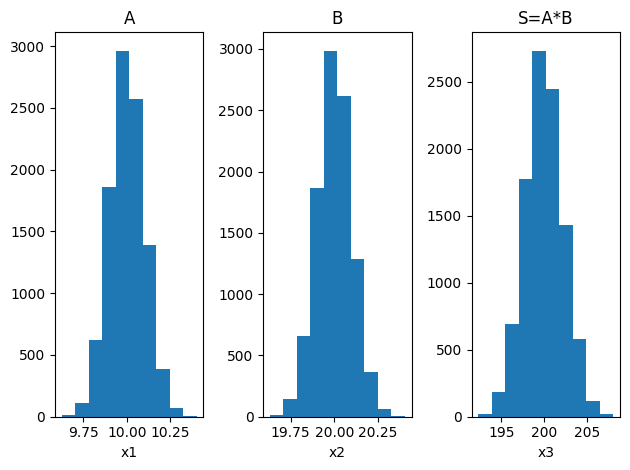

In [3]:
#| echo: off
data = [A, B, S]

xaxes = ['x1','x2','x3','x4']
yaxes = ['y1','y2','y3','y4']
titles = ['A','B','S=A*B'] 

f,a = plt.subplots(1,3)
for idx,ax in enumerate(a):
    ax.hist(data[idx])
    ax.set_title(titles[idx])
    ax.set_xlabel(xaxes[idx])
plt.tight_layout()

Le programme retourne `200.1 +- 2.3`.
En respectant le nombre de chiffre significatif, le résultat obtenu par la méthode de Monte-Carlo est donc 
$S=200\pm2\,\mathrm{cm^2}$. 
Ce résultat est bien compatible avec le résultat donné par la formule théorique pour un produit.
Ceci valide donc la méthode, il est présent possible de modifier le code ci-dessus pour des relations non-linéaire.

# Choix du nombre $N$ de tirages

Il est naturel de se demander quelle valeur de $N$ choisir.
- Un choix trop faible de $N$ entraîne une mauvaise représentation statistique, rendant l'estimation de l'incertitude peu précise.
- À l'inverse, un $N$ trop grand allonge inutilement le temps de calcul.

Observons l'évolution de l'erreur en fonction du nombre de tirages (voir graphique ci-dessous). Lorsque $N$ est inférieur à $10^3$, l'erreur reste significative. En revanche, pour  $N>10^3$, l'erreur se stabilise et converge vers la valeur attendue théoriquement par le calcul analytique.

Ainsi, un choix de $N=10^4$ constitue un bon compromis entre précision et temps de calcul. Cette valeur permet d'obtenir un résultat fiable en moins d'une seconde sur la plupart des ordinateurs.

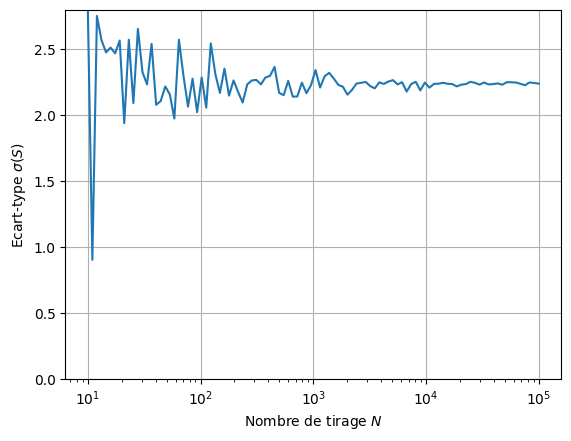

In [20]:
#| fold: true
a = 10.0 # mesure de a
da = 0.1 # incertitude associée
b = 20.0 # mesure de b
db = 0.1 # incertitude associée

ds_liste = []
N_liste = np.logspace( 1, 5, 100 )

for n in N_liste: # Nombre de tirages aléatoires
    N = int( n )
    A = np.random.normal( a, da, N ) # Liste contenant les valeurs simulees de a et b
    B = np.random.normal( b, db, N )

    S = A*B # Liste des surfaces calculée

    s, ds = np.mean( S ), np.std( S ) # Calcul du resultat

    ds_liste.append( ds )

plt.semilogx( N_liste, ds_liste )
plt.xlabel('Nombre de tirage $N$')
plt.ylabel('Ecart-type $\\sigma(S)$')
plt.ylim( 0, 2.8 )
plt.grid()

# Monte-Carlo et régression linéaire : Chute libre d'une bille

Cette méthode permet également de déterminer une incertitude sur des paramètres d'ajustement d'une courbe.
Par exemple, après avoir fait une régression linéaire sur 10 points, il est possible de tirer aléatoirement $N$ fois 10 points acceptables et effectuer $N$ ajustements.
On obtient donc $N$ valeurs de pente, puis une étude statistique nous permet de calculer l'incertitude sur la pente.

La différence est donc que le tirage aléatoire n'a pas lieu sur $N$ valeur mais uniquement sur une série de mesure (10 par exemple). Mais ce tirage a lieu $N$ fois.

L'objectif est de mesurer $g$, l'accélération de la pesanteur.
Pour cela on lâche une bille (qui est donc en chute libre verticale) et on repère sa position au cours du temps.
Pour cela on utilise une camera, la résolution temporelle est donc limité par la fréquence d'acquisition de la caméra.
De plus, plus la bille tombe vite et plus elle apparait floue sur l'image, l'incertitude sur la position augmente.

La vitesse est donnée par : $v=gt$, ainsi si on trace la vitesse en fonction du temps, on obtient une droite de pente $g$.
La vitesse est déterminée à chaque instant par la relation :
$$v_i = \frac{z_{i+1}-z_i}{\Delta t}$$

Or les positions $z_i$ sont de plus en plus mal repérées (flou de mouvement), on estime l'incertitude à $5\,\%$. 
On obtient le graphique ci-dessous. 
Les ellipses correspondent à l'intervalle où il est probable d'avoir la valeur réelle de la grandeur.

On effectue alors $N$ simulations compatibles avec cette première mesure.
On calcule alors $N$ pentes, il est ensuite possible d'effectuer une étude statistique.

In [ ]:
v0 = np.array( [0,9.8, 20.2, 28.3] ) # Liste des vitesses
dv = 0.05*v0 # 5% d'erreur
t0 = np.array( [0,1,2,3] ) # Liste des temps
dt = 0.1 # Erreur fixe de 0.1 s

N = 10000
G = [] # Liste contenant les valeurs de pentes simul%*é*)es
for i in range(N):
	v = normal( v0, dv )
	t = normal( t0, dt )
	pente, _, r, *_ = linregress( t, v )
	G.append( pente )
print( np.mean( C ), np.std( C ) ) # Etude statistique des pentes et affichage